# Expérimentations préliminaires — 4. Comparaison des modèles

Lit les prédictions sauvegardées par les notebooks 01 à 03 (exécuter ceux-ci d'abord) et les
compare à une **référence naïve** : probabilité constante égale au taux de victoire locale de
l'entraînement du pli (avantage de la glace seulement).

Toutes les prédictions portent sur les mêmes matchs (saisons 2021-22 à 2025-26).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from nhl_forecast.data.sources.predictions_externes import charger_compilees
from nhl_forecast.evaluation.preliminaire import (
    FIG_DIR,
    charger_predictions,
    exporter_tableau,
    formater,
    metriques,
    reference_naive,
    resultats_par_pli,
    resume,
)
from nhl_forecast.features.equipes import charger_equipes, construire_matchs
from nhl_forecast.visualization.style import COULEURS, MARQUEURS, TRAITS, appliquer_style

SAUVER = True
appliquer_style()

In [2]:
matchs = construire_matchs(charger_equipes())
preds = pd.concat([reference_naive(matchs), charger_predictions()], ignore_index=True)
ORDRE = ["Référence (taux local)", "Régression logistique", "XGBoost", "LSTM"]
preds["modele"] = pd.Categorical(preds["modele"], ORDRE, ordered=True)
preds = preds.sort_values(["modele", "pli"])
assert len(set(preds.groupby("modele", observed=True)["gameId"].apply(frozenset))) == 1  # mêmes matchs
preds.groupby("modele", observed=True).size()

C:\Users\tom_9\Projets\nhl-probabilistic-forecasting\src\nhl_forecast\features\equipes.py:182: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  matchs = matchs.astype({"visiteur": "int64"}).reset_index()


modele
Référence (taux local)    6560
Régression logistique     6560
XGBoost                   6560
LSTM                      6560
dtype: int64

## 1. Résumé : moyenne ± écart-type sur les 5 plis

Log loss et Brier : plus bas = meilleur. Accuracy : plus haut = meilleur.

In [3]:
tab_resume = resume(preds.assign(modele=preds["modele"].astype(str)))
if SAUVER:
    exporter_tableau(tab_resume, "exp_comparaison_resume")
formater(tab_resume)

Modèle,Log loss,Brier,Accuracy
Référence (taux local),0.6905 ± 0.0023,0.2487 ± 0.0011,0.5372 ± 0.0163
Régression logistique,0.7035 ± 0.0191,0.2516 ± 0.0056,0.5607 ± 0.0226
XGBoost,0.6740 ± 0.0080,0.2406 ± 0.0039,0.5820 ± 0.0197
LSTM,0.6880 ± 0.0035,0.2472 ± 0.0017,0.5555 ± 0.0079


## 2. Log loss par saison testée

In [4]:
par_pli = resultats_par_pli(preds.assign(modele=preds["modele"].astype(str)))
tab_ll = par_pli.pivot_table(index="Saison testée", columns="Modèle", values="Log loss")[ORDRE].reset_index()
tab_brier = par_pli.pivot_table(index="Saison testée", columns="Modèle", values="Brier")[ORDRE].reset_index()
tab_acc = par_pli.pivot_table(index="Saison testée", columns="Modèle", values="Accuracy")[ORDRE].reset_index()
if SAUVER:
    exporter_tableau(par_pli, "exp_comparaison_par_pli")
    exporter_tableau(tab_ll, "exp_comparaison_logloss_saisons")
formater(tab_ll)

Saison testée,Référence (taux local),Régression logistique,XGBoost,LSTM
2021-22,0.6905,0.7306,0.6749,0.6928
2022-23,0.6923,0.7159,0.6680,0.6864
2023-24,0.6900,0.6918,0.6664,0.6900
2024-25,0.6870,0.6848,0.6739,0.6837
2025-26,0.6928,0.6944,0.6867,0.6873


## 3. Score de Brier par saison testée

In [5]:
formater(tab_brier)

Saison testée,Référence (taux local),Régression logistique,XGBoost,LSTM
2021-22,0.2487,0.2597,0.2410,0.2496
2022-23,0.2496,0.2542,0.2376,0.2465
2023-24,0.2484,0.2481,0.2369,0.2479
2024-25,0.2469,0.2455,0.2406,0.2452
2025-26,0.2498,0.2502,0.2468,0.2468


## 4. Accuracy par saison testée

In [6]:
formater(tab_acc)

Saison testée,Référence (taux local),Régression logistique,XGBoost,LSTM
2021-22,0.5366,0.5671,0.5945,0.5549
2022-23,0.5236,0.5846,0.5930,0.5633
2023-24,0.5412,0.5686,0.5998,0.5633
2024-25,0.5625,0.5595,0.5686,0.5450
2025-26,0.5221,0.5236,0.5541,0.5511


## 5. Ensemble des matchs testés

Métriques calculées sur l'ensemble des 6 560 matchs testés (plis regroupés). L'erreur de
calibration attendue (ECE, 10 classes de même effectif) complète l'analyse de calibration.

In [7]:
def ece(y, p, n_classes=10):
    classes = pd.qcut(p, n_classes, labels=False, duplicates="drop")
    d = pd.DataFrame({"y": y, "p": p, "c": classes}).groupby("c")
    return float((d.size() / len(p) * (d["y"].mean() - d["p"].mean()).abs()).sum())


tab_global = pd.DataFrame([
    {"Modèle": m, **metriques(g["y"], g["p"]), "ECE": ece(g["y"].to_numpy(), g["p"].to_numpy())}
    for m, g in preds.groupby("modele", observed=True)
])
if SAUVER:
    exporter_tableau(tab_global, "exp_comparaison_global")
formater(tab_global)

Modèle,Log loss,Brier,Accuracy,ECE
Référence (taux local),0.6905,0.2487,0.5372,0.0143
Régression logistique,0.7035,0.2516,0.5607,0.0756
XGBoost,0.6740,0.2406,0.5820,0.0093
LSTM,0.6880,0.2472,0.5555,0.0423


## 6. Diagramme de fiabilité

Matchs testés regroupés en 10 classes de même effectif selon la probabilité prédite ; pour
chaque classe, fréquence observée de victoires locales en fonction de la probabilité moyenne
prédite. Un modèle parfaitement calibré suit la diagonale. Couleurs, traits et marqueurs
distincts permettent la lecture en noir et blanc.

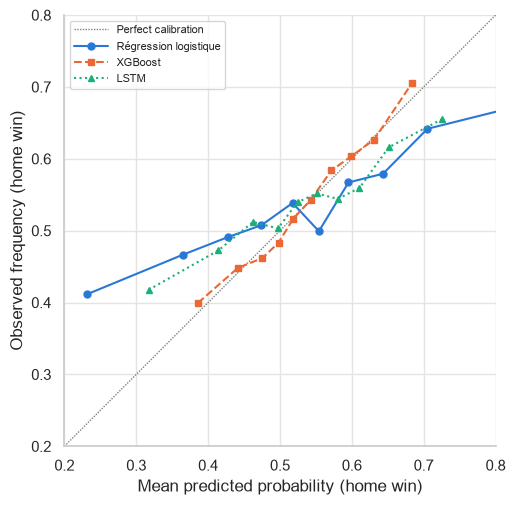

In [8]:
fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.plot([0.2, 0.8], [0.2, 0.8], color="0.5", linestyle=(0, (1, 1)), marker="", linewidth=1,
        label="Perfect calibration")
for i, m in enumerate(ORDRE[1:]):
    g = preds[preds["modele"] == m]
    c = pd.qcut(g["p"], 10, labels=False, duplicates="drop")
    pts = g.groupby(c)[["p", "y"]].mean()
    ax.plot(pts["p"], pts["y"], color=COULEURS[i], linestyle=TRAITS[i], marker=MARQUEURS[i],
            markersize=5, label=m)
ax.set(xlabel="Mean predicted probability (home win)", ylabel="Observed frequency (home win)",
       xlim=(0.2, 0.8), ylim=(0.2, 0.8), aspect="equal")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
if SAUVER:
    fig.savefig(FIG_DIR / "exp_fiabilite.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Sources externes

Prédictions publiées par des sites de prédiction (méthodes non divulguées), notées à la main
au fil du temps dans `data/external/` (un `README.md` par site). Seule la probabilité de
victoire locale est retenue ; les valeurs de 0 % / 100 % (prédictions non notées) sont exclues.
Chaque prédiction est appariée au match officiel (gameId) par
`scripts/compiler_predictions_externes.py`, qui produit un CSV par site
(`data/external/<site>/predictions_<site>.csv`, prédictions valides seulement).

**Attention :** les sources couvrent des saisons et des nombres de matchs très différents
(de 56 matchs à deux saisons complètes). Les métriques de deux sources ne sont comparables
que sur les **mêmes matchs** (section 7.3).

### 7.1 Couverture

In [9]:
ext = charger_compilees()
NB_MATCHS_SAISON = {"2017-18": 1271, "2018-19": 1271, "2021-22": 1312, "2024-25": 1312,
                    "2025-26": 1312}
lignes = []
for (src, saison), g in ext.groupby(["source", "Saison"], sort=False):
    lignes.append({"Source": src, "Saison": saison, "Début": g["Date"].min(), "Fin": g["Date"].max(),
                   "Matchs": len(g)})
tab_ext_couv = pd.DataFrame(lignes)
if SAUVER:
    exporter_tableau(tab_ext_couv, "exp_externes_couverture", 1)
formater(tab_ext_couv, 1)

Source,Saison,Début,Fin,Matchs
Forecheck,2017-18,2017-10-04,2018-04-08,1271
dRatings,2018-19,2018-10-03,2018-10-11,56
The Athletic,2018-19,2019-01-23,2019-03-08,148
Sports Club Stats,2018-19,2019-01-06,2019-02-21,127
MoneyPuck,2021-22,2022-01-03,2022-03-02,226
MySports.ai,2024-25,2024-10-05,2025-04-17,1309
MySports.ai,2025-26,2025-10-07,2026-04-16,1312


### 7.2 Performance de chaque source sur ses propres matchs

Chaque source est évaluée sur l'ensemble de ses matchs. Les sources portant sur des matchs
différents, ce tableau ne permet **pas** de les classer entre elles.

In [10]:
tab_ext_perf = pd.DataFrame([
    {"Source": src, "Saisons": ", ".join(sorted(g["Saison"].unique())), "Matchs": len(g),
     **metriques(g["Victoire locale"], g["Prob. victoire locale"])}
    for src, g in ext.groupby("source", sort=False)
])
if SAUVER:
    exporter_tableau(tab_ext_perf, "exp_externes_performance")
formater(tab_ext_perf)

Source,Saisons,Matchs,Log loss,Brier,Accuracy
Forecheck,2017-18,1271,0.6784,0.2422,0.5964
dRatings,2018-19,56,0.6768,0.2409,0.5893
The Athletic,2018-19,148,0.6400,0.2243,0.6351
Sports Club Stats,2018-19,127,0.6964,0.2515,0.5512
MoneyPuck,2021-22,226,0.6542,0.2309,0.6150
MySports.ai,"2024-25, 2025-26",2621,0.6810,0.2440,0.5555


Les sources de 2017-18 et 2018-19 sont antérieures à nos données d'expérimentation : elles
ne peuvent pas être comparées directement à nos modèles. Les échantillons de moins de
~300 matchs (dRatings, The Athletic, Sports Club Stats, MoneyPuck) ont une incertitude
importante : à titre indicatif, l'écart-type de la log loss moyenne sur 150 matchs est
d'environ 0,01 à 0,02, soit l'ordre de grandeur des écarts entre modèles.

### 7.3 Comparaison directe avec nos modèles (mêmes matchs)

Pour les sources qui couvrent nos saisons testées (MoneyPuck en 2021-22, MySports.ai en
2024-25 et 2025-26), nos modèles et la référence naïve du pli sont évalués exactement sur
les matchs prédits par la source.

In [11]:
nos = preds.assign(modele=preds["modele"].astype(str))[["modele", "gameId", "saison", "y", "p"]]
ext_nos = ext[ext["Saison"].isin(set(nos["saison"]))]
lignes = []
for (src, saison), g in ext_nos.groupby(["source", "Saison"], sort=False):
    communs = nos[nos["gameId"].isin(g["gameId"])]
    base = {"Source": src, "Saison": saison, "Matchs": int(g["gameId"].isin(communs["gameId"]).sum())}
    lignes.append({**base, "Modèle": src, **metriques(g["Victoire locale"], g["Prob. victoire locale"])})
    for m in ORDRE:
        c = communs[communs["modele"] == m]
        lignes.append({**base, "Modèle": m, **metriques(c["y"], c["p"])})
tab_ext_dir = pd.DataFrame(lignes)
if SAUVER:
    exporter_tableau(tab_ext_dir, "exp_externes_comparaison")
formater(tab_ext_dir)

Source,Saison,Matchs,Modèle,Log loss,Brier,Accuracy
MoneyPuck,2021-22,226,MoneyPuck,0.6542,0.2309,0.6150
MoneyPuck,2021-22,226,Référence (taux local),0.6918,0.2493,0.5265
MoneyPuck,2021-22,226,Régression logistique,0.6891,0.2458,0.5841
MoneyPuck,2021-22,226,XGBoost,0.6707,0.2390,0.6018
MoneyPuck,2021-22,226,LSTM,0.7189,0.2622,0.5000
MySports.ai,2024-25,1309,MySports.ai,0.6745,0.2409,0.5791
MySports.ai,2024-25,1309,Référence (taux local),0.6868,0.2468,0.5638
MySports.ai,2024-25,1309,Régression logistique,0.6846,0.2454,0.5607
MySports.ai,2024-25,1309,XGBoost,0.6736,0.2404,0.5699
MySports.ai,2024-25,1309,LSTM,0.6831,0.2449,0.5455


Même comparaison, matchs de chaque source regroupés (MySports.ai : 2024-25 et 2025-26
ensemble), log loss seulement :

In [12]:
lignes = []
for src, g in ext_nos.groupby("source", sort=False):
    communs = nos[nos["gameId"].isin(g["gameId"])]
    ligne = {"Source": src, "Saisons": ", ".join(sorted(g["Saison"].unique())), "Matchs": len(g),
             "Source externe": metriques(g["Victoire locale"], g["Prob. victoire locale"])["Log loss"]}
    for m in ORDRE:
        c = communs[communs["modele"] == m]
        ligne[m] = metriques(c["y"], c["p"])["Log loss"]
    lignes.append(ligne)
tab_ext_ll = pd.DataFrame(lignes)
if SAUVER:
    exporter_tableau(tab_ext_ll, "exp_externes_logloss")
formater(tab_ext_ll)

Source,Saisons,Matchs,Source externe,Référence (taux local),Régression logistique,XGBoost,LSTM
MoneyPuck,2021-22,226,0.6542,0.6918,0.6891,0.6707,0.7189
MySports.ai,"2024-25, 2025-26",2621,0.6810,0.6898,0.6895,0.6801,0.6852


## 8. Constats préliminaires

*(Valeurs de l'exécution du 2026-11-19 ; à revoir si les données ou les réglages changent.)*

**Nos modèles** (toutes les statistiques d'équipes des cinq sources, 1 052 variables ; ACP
selon le critère de Kaiser pour les trois modèles) :

- **XGBoost obtient les meilleurs scores** : log loss 0,6740 ± 0,0080, Brier 0,2406, accuracy
  58,2 % et la meilleure calibration (ECE 0,009, contre 0,014 pour la référence). C'est le seul
  modèle qui bat la référence naïve (0,6905) **dans chacun des cinq plis**. Les arbres retenus
  sont peu profonds (2 à 4) et peu nombreux (32 à 120) : les relations utiles semblent
  surtout simples une fois les variables agrégées. Le gain est réparti sur de nombreuses
  composantes (la plus utilisée, CP1, ne compte que pour ≈ 2,6 % du gain total), ce qui rend
  l'importance des variables difficile à interpréter après l'ACP.
- **Le LSTM bat à peine la référence** : log loss 0,6880 ± 0,0035 contre 0,6905. Il fait mieux
  dans trois plis, égal dans un, et moins bien en 2021-22. Il est moins bien calibré
  (ECE 0,042). L'arrêt précoce retient 10 à 20 époques ; au-delà, la perte de validation
  remonte (surapprentissage). L'ACP résume les 525 statistiques d'un match en 89 composantes
  (≈ 88 % de la variance). Avec ≈ 1 300 matchs par saison, apprendre la forme des équipes à
  partir des séquences brutes reste plus difficile que d'utiliser des moyennes pré-calculées.
- **La régression logistique sans pénalité fait moins bien que la référence** : log loss
  0,7035 ± 0,0191, avec la pire calibration (ECE 0,076). Elle surapprend : 111 à 149
  coefficients sont estimés par maximum de vraisemblance, sans régularisation. L'effet est le
  plus fort au pli 1 (0,731), entraîné sur la seule saison 2020-21 raccourcie (868 matchs),
  puis diminue quand l'entraînement s'allonge (0,685 au pli 4, seul pli où elle bat la
  référence). Une pénalité (ridge / L2) ou un nombre plus petit de composantes devrait
  corriger ce problème.
- **Ajouter toutes les statistiques n'améliore pas les prédictions.** Une version antérieure
  de ces expériences, limitée à 29 statistiques, donnait des log loss plus basses
  (régression logistique 0,666, XGBoost 0,669, LSTM 0,673). La réduction de dimension et la
  sélection de variables seront donc un volet important du projet.
- **L'écart entre XGBoost et le LSTM (≈ 0,014) est du même ordre que la variabilité entre
  saisons** (écart-type de 0,004 à 0,019 selon le modèle), même s'il va dans le même sens
  dans les cinq plis : un test apparié (bootstrap ou Diebold-Mariano) reste nécessaire avant
  de conclure.
- **L'accuracy (53,7 % pour la référence, 55,6 à 58,2 % pour nos modèles) distingue peu les
  modèles** ; la log loss et le score de Brier sont plus informatifs pour juger des
  probabilités.

**Sources externes** (section 7) :

- Sur les **mêmes matchs**, XGBoost fait aussi bien que MySports.ai (2 621 matchs, 2024-25 et
  2025-26) : log loss 0,680 contre 0,681 ; le LSTM obtient 0,685, la régression logistique
  0,690 et la référence 0,690. MoneyPuck (226 matchs, 2021-22) fait mieux que tous nos
  modèles : 0,654 contre 0,671 pour XGBoost, 0,689 pour la régression logistique et 0,719
  pour le LSTM. L'échantillon MoneyPuck est toutefois trop petit pour conclure.
- Les sources de 2017-19 ne sont pas comparables à nos modèles (autres saisons) ; leur
  log loss va de 0,640 (The Athletic, 148 matchs) à 0,696 (Sports Club Stats, 127 matchs).
- Les sites ne publient pas leur méthode ni toujours le moment de la prédiction (avant ou
  après l'annonce des gardiens) : ces comparaisons restent indicatives.

Pistes : régularisation de la régression logistique, statistiques de joueurs et de gardiens
(gardien partant), sélection ou réduction des variables, utilisation de la saison précédente
en début de saison, réglage plus poussé des hyperparamètres et recalibration.